In [2]:
import pandas as pd
import random

In [3]:
## --> One Dice thrown : 

# L = []
# for i in range(10000):
#     L.append(random.randint(1,6))


## --> Two Dice thrown : 

L = []
for i in range(10000):
    a = random.randint(1 , 6)
    b = random.randint(1 , 6)

    L.append(a + b)
    

In [4]:
len(L)

10000

In [5]:
L[:5]


[12, 6, 6, 5, 11]

In [6]:
s = (pd.Series(L).value_counts() / pd.Series(L).value_counts().sum()).sort_index()
s

2     0.0320
3     0.0570
4     0.0820
5     0.1120
6     0.1336
7     0.1668
8     0.1379
9     0.1112
10    0.0823
11    0.0584
12    0.0268
Name: count, dtype: float64

<Axes: >

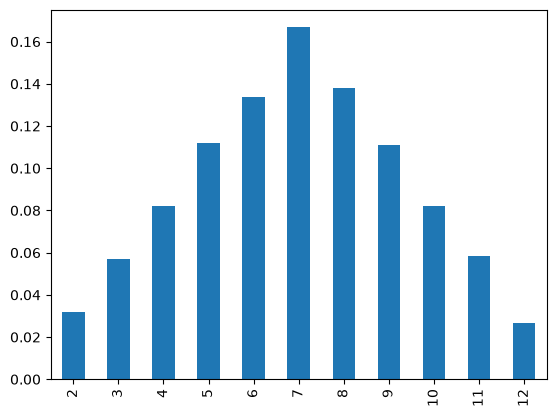

In [7]:
s.plot(kind = 'bar')



In [8]:
import numpy as np

np.cumsum(s)

2     0.0320
3     0.0890
4     0.1710
5     0.2830
6     0.4166
7     0.5834
8     0.7213
9     0.8325
10    0.9148
11    0.9732
12    1.0000
Name: count, dtype: float64

<Axes: >

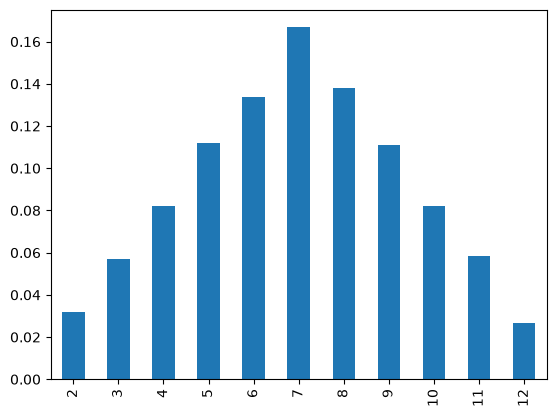

In [9]:
## Commulative Mass Function ( CMF ) :

s.plot(kind='bar')

<Axes: >

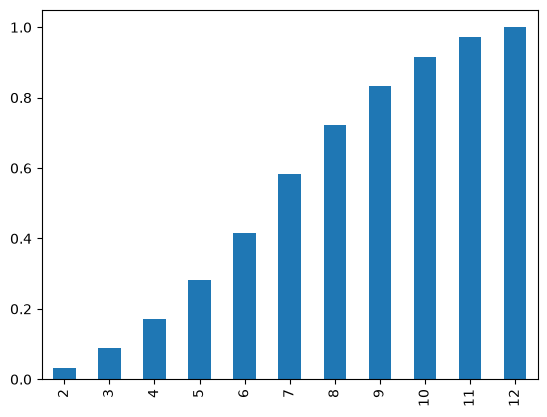

In [10]:
## cummulative distribution function ( CDF ) :

np.cumsum(s).plot(kind='bar')

##  Parametric Density Estimations : 

In [11]:
import matplotlib.pyplot as plt
import numpy as np
from numpy.random import normal

sample = normal(loc=50, scale=5,size=1000)

In [12]:
sample

array([40.16210681, 49.45859027, 46.73909876, 56.10855035, 41.27481499,
       47.03049457, 41.44698182, 54.24957246, 54.31880916, 49.86023534,
       44.17165222, 53.73115191, 54.23279974, 51.57853872, 41.77632556,
       55.57813001, 39.94176877, 47.61309851, 48.01807406, 51.00878789,
       50.08959261, 53.77664923, 50.68829703, 54.03323473, 47.40263372,
       51.11765962, 52.16061008, 45.81335781, 52.88163696, 46.73566312,
       58.34828669, 51.00961156, 46.47745099, 46.70741679, 50.42829809,
       49.50985505, 46.14835566, 55.61658148, 45.79005315, 50.67572161,
       51.27135893, 55.26042145, 54.12403925, 49.93926535, 41.83453985,
       50.53198717, 49.54829769, 46.36277395, 45.78078556, 47.30535565,
       43.43063454, 47.38841876, 51.21783897, 45.13054506, 50.24097248,
       51.71810435, 45.71709975, 54.43864294, 48.82296465, 43.75123705,
       49.94720767, 43.60644516, 50.5004379 , 46.77921152, 43.56350679,
       50.77800563, 61.91086867, 50.73442646, 54.02601217, 48.01

In [13]:
sample.mean()

np.float64(49.97620224933333)

(array([  3.,  14.,  59., 133., 236., 253., 185.,  84.,  26.,   7.]),
 array([32.52269171, 35.88144191, 39.24019211, 42.59894232, 45.95769252,
        49.31644272, 52.67519293, 56.03394313, 59.39269333, 62.75144353,
        66.11019374]),
 <BarContainer object of 10 artists>)

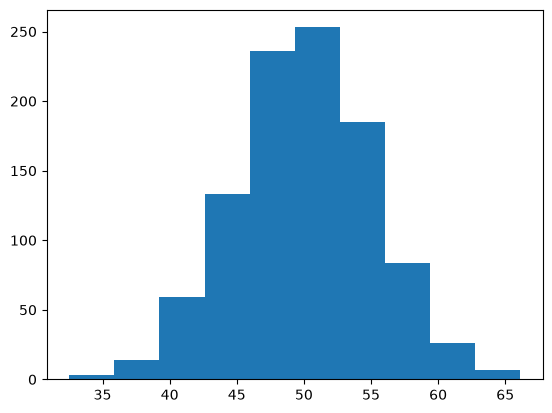

In [14]:
# plot histogram to understand the distribution of data :

plt.hist(sample , bins = 10)

In [15]:
# calculate sample mean and sample std dev :

sample_mean = sample.mean()
sample_std = sample.std()

In [16]:
# fit the distribution with the above parameters : 

from scipy.stats import norm
dist = norm(sample_mean, sample_std)




In [17]:
values = np.linspace(sample.min(),sample.max(),100)

In [18]:
sample.max()

np.float64(66.11019373811172)

In [19]:
probabilities = [dist.pdf(value) for value in values]


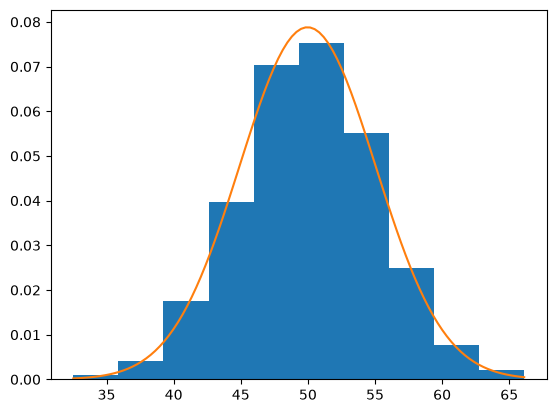

In [20]:
# plot the histogram and pdf :


plt.hist(sample,bins=10,density=True)
plt.plot(values,probabilities)

C:\Users\ANUBHAV\AppData\Local\Temp\ipykernel_34336\1482356190.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sample)


<Axes: ylabel='Density'>

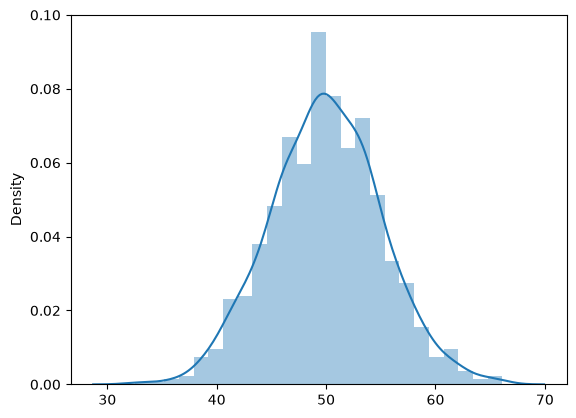

In [21]:
import seaborn as sns
sns.distplot(sample)

## Non - Parametric Density Estimations : 

In [22]:
### KDE : 

In [23]:
# generate a sample
sample1 = normal(loc=20, scale=5, size=300)
sample2 = normal(loc=40, scale=5, size=700)
sample = np.hstack((sample1, sample2))

In [24]:
sample

array([18.20506918, 22.25062143, 16.70189573, 13.62989384, 17.39612236,
       14.4094092 , 21.39921451, 16.31976489, 17.50077331, 19.415701  ,
       17.39301173, 18.42806136, 17.17434084, 27.01208272, 25.23753927,
       27.69069843, 11.59489584, 15.80014256, 24.51767608, 21.70146238,
       22.77488606, 16.05045908, 26.2294791 , 18.36342357, 20.53381037,
       17.84701855, 17.10778466, 22.26884536, 22.33842462, 15.54435451,
       21.60464603, 21.64965601, 21.69160475, 13.10532763, 22.38365291,
       14.36531588, 25.61336164, 15.24459974,  6.20641576, 17.36826522,
       24.13794754, 14.33123278, 15.17986299, 21.57107791, 30.38123307,
       20.22058737, 17.35069041, 21.26849511, 15.17445646, 12.06216148,
       22.2886563 ,  9.04910793, 21.28052941, 28.26474268, 23.70663562,
       25.39098138, 19.02339756, 18.28826071, 12.13593397, 19.4039206 ,
       25.75280047, 26.52311901, 18.16731073,  9.81952306, 19.66225818,
       16.7101969 , 24.40853628, 21.19069524, 25.12652305, 17.49

(array([ 2.,  0.,  0.,  2.,  4.,  5.,  6.,  9.,  9., 15., 19., 27., 17.,
        27., 20., 27., 19., 19., 13., 19., 13.,  9.,  3., 12., 15., 10.,
        21., 16., 21., 31., 44., 36., 37., 50., 59., 44., 55., 43., 46.,
        33., 36., 20., 25., 21., 12.,  7.,  9.,  1.,  7.,  5.]),
 array([ 6.20641576,  7.15305769,  8.09969962,  9.04634155,  9.99298348,
        10.93962541, 11.88626735, 12.83290928, 13.77955121, 14.72619314,
        15.67283507, 16.619477  , 17.56611893, 18.51276086, 19.45940279,
        20.40604472, 21.35268666, 22.29932859, 23.24597052, 24.19261245,
        25.13925438, 26.08589631, 27.03253824, 27.97918017, 28.9258221 ,
        29.87246403, 30.81910597, 31.7657479 , 32.71238983, 33.65903176,
        34.60567369, 35.55231562, 36.49895755, 37.44559948, 38.39224141,
        39.33888334, 40.28552528, 41.23216721, 42.17880914, 43.12545107,
        44.072093  , 45.01873493, 45.96537686, 46.91201879, 47.85866072,
        48.80530265, 49.75194459, 50.69858652, 51.64522845,

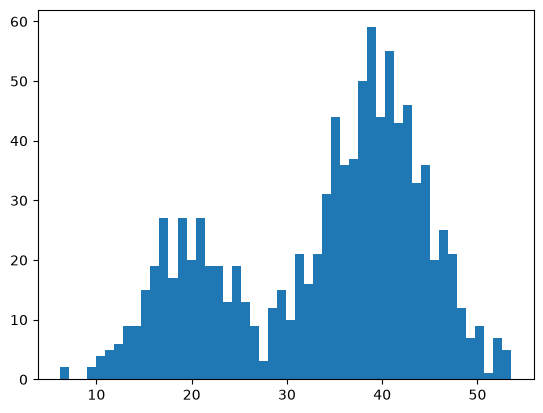

In [25]:
# plot histogram bins=50
plt.hist(sample,bins=50)

In [40]:
from sklearn.neighbors import KernelDensity

model = KernelDensity(bandwidth=5, kernel='gaussian')

# convert data to a 2D array
sample = sample.reshape((len(sample), 1))


In [41]:

model.fit(sample)


,"bandwidth bandwidth: float or {""scott"", ""silverman""}, default=1.0The bandwidth of the kernel. If bandwidth is a float, it defines thebandwidth of the kernel. If bandwidth is a string, one of the estimationmethods is implemented.",5
,"algorithm algorithm: {'kd_tree', 'ball_tree', 'auto'}, default='auto'The tree algorithm to use.",'auto'
,"kernel kernel: {'gaussian', 'tophat', 'epanechnikov', 'exponential', 'linear', 'cosine'}, default='gaussian'The kernel to use.",'gaussian'
,"metric metric: str, default='euclidean'Metric to use for distance computation. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.Not all metrics are valid with all algorithms: refer to thedocumentation of :class:`BallTree` and :class:`KDTree`. Note that thenormalization of the density output is correct only for the Euclideandistance metric.",'euclidean'
,"atol atol: float, default=0The desired absolute tolerance of the result. A larger tolerance willgenerally lead to faster execution.",0
,"rtol rtol: float, default=0The desired relative tolerance of the result. A larger tolerance willgenerally lead to faster execution.",0
,"breadth_first breadth_first: bool, default=TrueIf true (default), use a breadth-first approach to the problem.Otherwise use a depth-first approach.",True
,"leaf_size leaf_size: int, default=40Specify the leaf size of the underlying tree. See :class:`BallTree`or :class:`KDTree` for details.",40
,"metric_params metric_params: dict, default=NoneAdditional parameters to be passed to the tree for use with themetric. For more information, see the documentation of:class:`BallTree` or :class:`KDTree`.",None
Name,Type,Value
"bandwidth_ bandwidth_: floatValue of the bandwidth, given directly by the bandwidth parameter orestimated using the 'scott' or 'silverman' method... versionadded:: 1.0",int,5


In [42]:
values = np.linspace(sample.min(),sample.max(),100)
values = values.reshape((len(values), 1))

In [43]:
probabilities = model.score_samples(values)
probabilities = np.exp(probabilities)



'''
score_samples(values) returns the log-density estimate of the input samples values.
This is because the score_samples() method of the KernelDensity class returns the logarithm of 
the probability density estimate rather than the actual probability density estimate.


'''




'\nscore_samples(values) returns the log-density estimate of the input samples values.\nThis is because the score_samples() method of the KernelDensity class returns the logarithm of \nthe probability density estimate rather than the actual probability density estimate.\n\n\n'

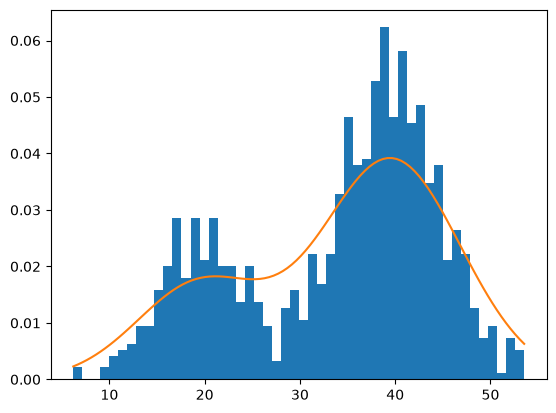

In [44]:
plt.hist(sample, bins=50, density=True)
plt.plot(values[:], probabilities)
plt.show()

<Axes: ylabel='Density'>

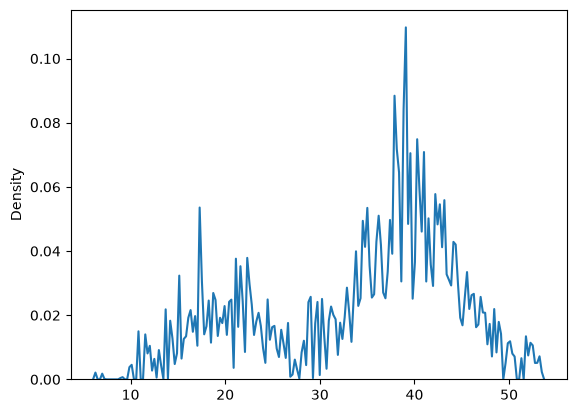

In [45]:
import seaborn as sns

sns.kdeplot(sample.reshape(1000),bw_adjust=0.02)

In [46]:
df = sns.load_dataset('iris')
df


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


<Axes: xlabel='sepal_length', ylabel='Density'>

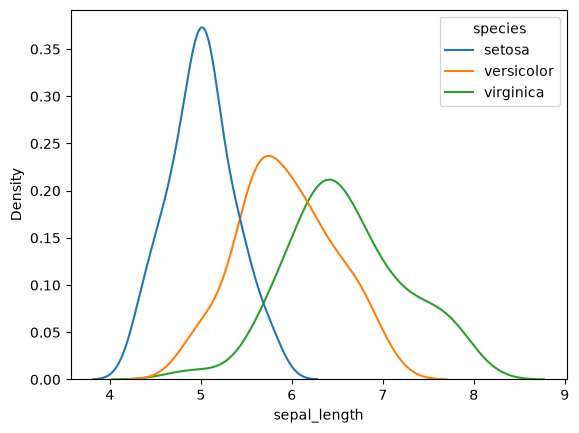

In [47]:
sns.kdeplot(data=df,x='sepal_length',hue='species')
